In [31]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info.states.statevector import Statevector
from qiskit.circuit.library import (
    standard_gates as gates,
    MCXGate,
    RYGate,
    MCMTGate,
    ZGate,
    SwapGate,
    HGate,
    StatePreparation,
)

import matplotlib.pyplot as plt
import sys
import numpy as np
import math
import argparse
import os

from curl_curl_functions_pi import (
    streaming_axz,
    streaming_ayz,
    streaming_azz,
    save_statevector,
    summations,
    summations_pi,
    relaxation_param,
    relaxation_param_pi,
    calculate_b_and_plot,
    zxy_to_xyz,
    zxy_to_yzx,
    get_az_ay_ax,
    padding_as,
    flatten_as,
    apply_boundary_conditions,
    check_convergence,
    save_statevector_with_pi,
    quantum_pi_rotations,
)

np.set_printoptions(threshold=sys.maxsize, linewidth=200)
path = "/home/tmvshinde/E-Folder/PHD/Codes/curl_curl/curl_pi_timestep/"

if not os.path.exists(path):
    os.makedirs(path, exist_ok=True)

In [32]:
num_grid_dir_one = 8
nx, ny, nz = num_grid_dir_one, num_grid_dir_one, num_grid_dir_one
ax = np.zeros((nz, nx - 1, ny), dtype=np.float64)
ay = np.zeros((nz, nx, ny - 1), dtype=np.float64)
az = np.zeros((nz - 1, nx, ny), dtype=np.float64)


ax = np.arange(1, nz * (nx-1) * ny + 1).reshape(nz, nx-1, ny)
ay = np.arange(1, nz * nx * (ny-1) + 1).reshape(nz, nx, ny-1)
az = np.arange(1, (nz-1) * nx * ny + 1).reshape(nz-1, nx, ny)
# # # print(ax)

jx = np.zeros((nx - 1, ny, nz), dtype=np.float64)
jy = np.zeros((ny - 1, nz, nx), dtype=np.float64)
jz = np.zeros((nz - 1, nx, ny), dtype=np.float64)

jz[:, nx // 2, ny // 2] = 1
jx[:,nx//2,ny//2] = 1 * 2
jy[:,nx//2,ny//2] = 1 * 4

jx = np.pad(jx, pad_width=((0, 1), (0, 0), (0, 0)), mode="constant")
jy = np.pad(jy, pad_width=((0, 1), (0, 0), (0, 0)), mode="constant")
jz = np.pad(jz, pad_width=((0, 1), (0, 0), (0, 0)), mode="constant")

jx_flat, jy_flat, jz_flat = flatten_as(jx, jy, jz)

beta = 0.8
timesteps = 2
bool_print = True
# print(ax)
# print(ay)
# print(az)


In [33]:
for t in range(timesteps):

    print(f"============Iteration {t}========= ")

    axz = ax
    ayz = ay
    azz = az

    # ax_new = np.zeros((nx - 1, ny, nz), dtype=np.float64)
    # ay_new = np.zeros((ny - 1, nz, nx), dtype=np.float64)
    # az_new = np.zeros((nz - 1, nx, ny), dtype=np.float64)

    axz, ayz, azz = padding_as(axz, ayz, azz)
    axz_flat, ayz_flat, azz_flat = flatten_as(axz, ayz, azz)

    num_q_ax = np.log2(axz_flat.shape[0]).astype(int)
    if bool_print==True:
        print("num_q_ax: ", num_q_ax)

    state_vec = np.concatenate(
        (
            axz_flat,
            ayz_flat,
            azz_flat,
            jz_flat,
            jy_flat,
            jx_flat,
        )
    )

    state_vec = np.pad(
        state_vec,
        (0, 2 ** math.ceil(np.log2(state_vec.shape[0])) - state_vec.shape[0]),
        mode="constant",
    )

    if bool_print==True:
        print("state_vec shape: ", state_vec.shape[0])

    # calculating the number of qubits needed to represent the ax, ay, az, jx, jy, jz arrays as a quantum state vector
    num_qubits_statevec = np.log2(state_vec.shape[0]).astype(int)

    if bool_print==True:
        print("num_qubits_statevec: ", num_qubits_statevec)

    num_qubits_eqs = 2 
    num_qubits_h_copies = 3
    num_qubits_ancilla = 1
    num_qubits_timestep = 1
    num_qubits_total = num_qubits_statevec + num_qubits_eqs + num_qubits_h_copies + num_qubits_ancilla
    num_qubits_total_timestep = num_qubits_total + num_qubits_timestep
    if bool_print==True:
        print("total_qubits: ", num_qubits_total)
        print("num_of_states: ", 2 ** num_qubits_total)

    num_q_xyz = num_qubits_statevec - 3
    numqz = 0
    numqx = num_q_xyz - 2 * (num_q_xyz // 3)
    numqy = num_q_xyz - numqx

    if bool_print==True:
        print("numqz: ", numqz, " numqx: ", numqx, "numqy: ", numqy)

    # anc = QuantumRegister(2, "")
    # data = QuantumRegister(4, "data")
    # work = QuantumRegister(2, "work")
    qc = QuantumCircuit(num_qubits_total_timestep)

    statevec_norm = np.linalg.norm(state_vec)
    if bool_print==True:
        print("Norm of the state vector before normalization: ", statevec_norm)
    state_vec = state_vec / statevec_norm
    qubits_for_init = np.arange(0, num_qubits_statevec)
    qc.initialize(state_vec, range(0, num_qubits_statevec), normalize=False)
    
    # =====================================
    #creating a superposition to get 3 h copies of ax, ay, az, jz, jx, jy
    # =====================================
    qc.h(num_qubits_statevec)
    qc.h(num_qubits_statevec + 1)

    # =====================================
    #shifting one set jz, jy,jx for next timestep
    # =====================================
    qc.barrier()
    qc.ccx(num_qubits_statevec, num_qubits_statevec + 1, num_qubits_total_timestep - 1)

    # =====================================
    # doing the pi transformations
    # shifting the az, ax, ay to the correct positions for star oracle
    # =====================================
    ctrlsstates_pi = ["001", "010"]
    ctrls_pi = [num_qubits_statevec, num_qubits_statevec + 1, num_qubits_statevec -1 ]

    qc_zxy_to_yzx = quantum_pi_rotations(num_qubits_total, numqz, numqx, numqy, ctrls_pi, ctrlsstates_pi[0])
    qc_zxy_to_xyz = quantum_pi_rotations(num_qubits_total, numqz, numqx, numqy, ctrls_pi, ctrlsstates_pi[1])
    
    # qc.barrier()
    qc = qc.compose(qc_zxy_to_yzx)

    # # qc.barrier()
    qc = qc.compose(qc_zxy_to_xyz.inverse())

    # =====================================
    #swapping jy, jx
    # =====================================
    qc.barrier()

    qc.append(MCXGate(3, ctrl_state="101"), ctrls_pi + [num_qubits_statevec -3])
    qc.append(
            SwapGate().control(3, ctrl_state="011"),
            [num_qubits_statevec - 3, num_qubits_statevec, num_qubits_statevec + 1] + [num_qubits_statevec-1,num_qubits_statevec-2]
        )

    qc.append(
            SwapGate().control(3, ctrl_state="101"),
            [num_qubits_statevec - 3, num_qubits_statevec, num_qubits_statevec + 1] + [num_qubits_statevec-1,num_qubits_statevec-2]
        )
    
    # =====================================
    # pi rotations and swapping js are done 
    # =====================================

    # =====================================
    # Starting the star oracle
    # =====================================
    qc.barrier()
    qc.h(range(num_qubits_statevec + 2, num_qubits_total - 1))

    ctrls_az = "01"
    ctrls_ax = "00"
    ctrls_ay = "10"
    num_copies = 5
    ctrls_copies = []
    num_h_qubits = num_qubits_total - num_qubits_statevec - 3
    for i in range(num_copies):
        bin_copies = bin(i)[2:].zfill(num_h_qubits)
        ctrls_copies.append(bin_copies)
    
    if bool_print==True:
        print("ctrls_copies: ", ctrls_copies)

    qc.barrier()
    qcz = streaming_azz(
        num_qubits_total, numqx, numqz, ctrls_az, ctrls_copies
    )
    qc = qc.compose(qcz)
    # # qc.append(qcz.to_instruction(label="Z"), range(num_qubits_total + 1))

    qc.barrier()
    qcx = streaming_axz(
        num_qubits_total, numqx, numqy, ctrls_ax, ctrls_copies
    )
    qc = qc.compose(qcx)
    # # qc.append(qcx.to_instruction(label="X"), range(num_qubits_total + 1))

    qc.barrier()
    qcy = streaming_ayz(
        num_qubits_total, numqy, numqz, ctrls_ay, ctrls_copies
    ) 
    qc = qc.compose(qcy)
    # qc.append(qcy.to_instruction(label="Y"), range(num_qubits_total + 1))

    # =====================================
    # Star oracle done
    # =====================================

    # =====================================
    # Relaxation parameter
    # =====================================
    # qc.barrier()
    # angle_p = [
    #     math.acos(beta / 4),
    #     math.asin(-beta / 4),
    #     math.acos(1 - beta),
    #     math.asin(1 - beta),
    # ]

    angle_p = [
            math.acos(beta / 4),
            math.asin(-beta/4),
            math.acos(1 - beta),
            math.asin(1 - beta),
        ]

    state_ctl = [
        "0",
        "1",
    ]
    ctrls = ["000", "100", "001", "101", "010"]
    ctrls = ["000", "010", "100", "110"]

    qcrp = relaxation_param_pi(ctrls, angle_p, num_qubits_total)
    qc = qc.compose(qcrp)
    # qc.barrier()

    # =====================================
    # Interference summation
    # =====================================

    qcsum = summations_pi(num_qubits_total_timestep-2, num_qubits_statevec+2)
    # gate = qcsum.to_gate(label="U")
    # qcs = gate.control(1, ctrl_state="0")

    qc = qc.compose(qcsum)

    # qc.append(qcs, [num_qubits_total] + list(range(num_qubits_total)))
    qc.barrier()
    
    # =====================================
    # Saving the statevector and getting results from the simulator
    # for timestepping run 67 - Start index: 34304 - has values of ax, ay, az, jx, jy, jz
    # for next timestep 
    # they need to be divided by 4 as the transformations add factor 4
    # =====================================s
    qc.save_statevector()
    simulator = AerSimulator()
    compiled_circuit = transpile(qc, simulator)
    result = simulator.run(compiled_circuit).result()
    final_statevector = np.asarray(result.get_statevector())
    
    hs = 2 + 3
    hadamardss = 5
    hadamard_copie = hs + (hadamardss)

    final_statevector_ = (
        final_statevector.real * statevec_norm * np.sqrt(2) ** (hadamard_copie)
    )
    idddd = nx * ny * nz
    save_statevector_with_pi(final_statevector, statevec_norm, hadamard_copie, idddd, path, nx)

    axn, ayn, azn = get_az_ay_ax(final_statevector_, nx, ny, nz, path)

    axn, ayn, azn = apply_boundary_conditions(axn, ayn, azn)

    norm_convergx, norm_convergy, norm_convergz = check_convergence(ax, ay, az, axn, ayn, azn)
    
    if norm_convergz < 0.0000001:
        break

    az = np.copy(azn)
    ax = np.copy(axn)
    ay = np.copy(ayn)

    # boundary conditions
    ax, ay, az = apply_boundary_conditions(ax, ay, az)

    if bool_print==False:
        print("ax", ax)
        print("ay", ay)
        print("az", az)



============Iteration 0========= 
num_q_ax:  9
state_vec shape:  4096
num_qubits_statevec:  12
total_qubits:  18
num_of_states:  262144
numqz:  0  numqx:  3 numqy:  6
Norm of the state vector before normalization:  9498.253471033504
ctrls_copies:  ['000', '001', '010', '011', '100']
['0100000', '0110000', '0101000', '0111000', '0100100']
512
1024
1536

--- ax ---


--- ay ---


--- az ---

norm of ax for converg : 15001155.120000001
norm of ay for converg : 18558852.479999997
norm of az for converg : 13194818.280000001
============Iteration 1========= 
num_q_ax:  9
state_vec shape:  4096
num_qubits_statevec:  12
total_qubits:  18
num_of_states:  262144
numqz:  0  numqx:  3 numqy:  6
Norm of the state vector before normalization:  6855.3920442232875
ctrls_copies:  ['000', '001', '010', '011', '100']
['0100000', '0110000', '0101000', '0111000', '0100100']
512
1024
1536

--- ax ---


--- ay ---


--- az ---

norm of ax for converg : 681404.5440000016
norm of ay for converg : 3278735.05599



In [34]:
qc.draw("mpl", filename=path + "final_circuit.png", scale=1.5)

In [35]:
qc.draw("latex_source",filename=path+"circuit_layer_2.txt"
)

'\\documentclass[border=2px]{standalone}\n\n\\usepackage[braket, qm]{qcircuit}\n\\usepackage{graphicx}\n\n\\begin{document}\n\\scalebox{1.0}{\n\\Qcircuit @C=1.0em @R=0.2em @!R { \\\\\n\t \t\\nghost{{q}_{0} :  } & \\lstick{{q}_{0} :  } & \\multigate{11}{|\\psi\\rangle\\,(\\mathrm{0,0,0,0,...})}_<<<{0} \\barrier[0em]{18} & \\qw & \\qw & \\qswap & \\qw & \\qw & \\qswap & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qswap & \\qw & \\qw & \\qswap \\barrier[0em]{18} & \\qw & \\qw & \\qw & \\qw \\barrier[0em]{18} & \\qw & \\qw \\barrier[0em]{18} & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\targ & \\ctrl{1} & \\qw & \\ctrl{1} & \\qw & \\ctrl{1} & \\targ & \\qw & \\ctrl{1} \\barrier[0em]{18} & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw \\barrier[0em]{18} & \\qw & \\qw & \\qw & \\qw & \\qw & \\targ 

In [36]:


# # print(new_qc.count_ops())
# transpiled_qc = transpile(qc, basis_gates=["h", "s", "cx", "t"], optimization_level=3)

# print(transpiled_qc.count_ops())
# # print(qc.depth())
# # print(transpiled_qc.depth())

Original circuit:
     ┌───────┐
q_0: ┤0      ├
     │       │
q_1: ┤1 Rccx ├
     │       │
q_2: ┤2      ├
     └───────┘

Decomposed circuit:
                                                      
q_0: ────────────────────────■────────────────────────
                             │                        
q_1: ────────────■───────────┼─────────■──────────────
     ┌───┐┌───┐┌─┴─┐┌─────┐┌─┴─┐┌───┐┌─┴─┐┌─────┐┌───┐
q_2: ┤ H ├┤ T ├┤ X ├┤ Tdg ├┤ X ├┤ T ├┤ X ├┤ Tdg ├┤ H ├
     └───┘└───┘└───┘└─────┘└───┘└───┘└───┘└─────┘└───┘


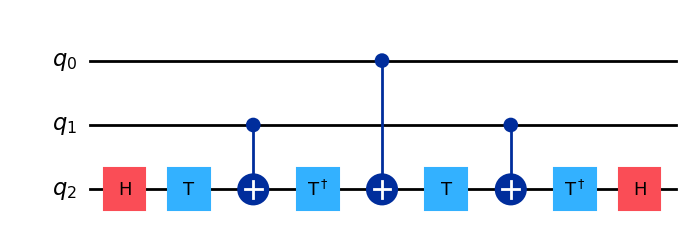

In [2]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import RCCXGate

# Create a circuit with 3 qubits
qc = QuantumCircuit(3)

# Add the relative-phase Toffoli (RCCX) gate
qc.append(RCCXGate(), [0, 1, 2])

print("Original circuit:")
print(qc)

# Decompose the RCCX gate
decomposed = qc.decompose()

print("\nDecomposed circuit:")
print(decomposed.draw("text"))
decomposed.draw("mpl")